In [6]:
from dataretrieval import nwis

In [7]:
# groundwater data
site = '395136108210004'
display(nwis.get_record(sites=site, service='site'))

C:\Users\katel\AppData\Local\Temp\ipykernel_8948\3457439203.py:3: DeprecationWarning: `nwis.get_record` is deprecated and will be removed from `dataretrieval` on or after 2027-05-06; use the appropriate `waterdata.get_*()` for the service you need instead.
  display(nwis.get_record(sites=site, service='site'))


,agency_cd,site_no,station_nm,site_tp_cd,lat_va,long_va,dec_lat_va,dec_long_va,coord_meth_cd,coord_acy_cd,...,reliability_cd,gw_file_cd,nat_aqfr_cd,aqfr_cd,aqfr_type_cd,well_depth_va,hole_depth_va,depth_src_cd,project_no,geometry
0,USGS,395136108210004,SC00209824CBB4 TH75-13U,GW,395136.48,1082103.44,39.860133,-108.350956,Z,E,...,C,Y Y,N300COPLTS,120TRTR,U,249.5,250,D,D9Y,POINT (-108.35096 39.86013)


In [8]:
df_gwl_co = nwis.get_record(sites=site, service='dv', start='2010-06-22', end='2026-10-01').reset_index()
display(df_gwl_co.head())

C:\Users\katel\AppData\Local\Temp\ipykernel_8948\4101342356.py:1: DeprecationWarning: `nwis.get_record` is deprecated and will be removed from `dataretrieval` on or after 2027-05-06; use the appropriate `waterdata.get_*()` for the service you need instead.
  df_gwl_co = nwis.get_record(sites=site, service='dv', start='2010-06-22', end='2026-10-01').reset_index()


,datetime,00010_Maximum,00010_Maximum_cd,00010_Minimum,00010_Minimum_cd,00010_Mean,00010_Mean_cd,00020_Maximum,00020_Maximum_cd,00020_Minimum,...,00045_Sum_cd,00052_Maximum,00052_Maximum_cd,00052_Minimum,00052_Minimum_cd,00052_Mean,00052_Mean_cd,72019_Mean,72019_Mean_cd,site_no
0,2010-06-22 00:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,61.02,A,395136108210004
1,2010-06-23 00:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,61.08,A,395136108210004
2,2010-06-24 00:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,61.04,A,395136108210004
3,2010-06-25 00:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,61.00,A,395136108210004
4,2010-06-26 00:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,60.99,A,395136108210004


In [9]:
df_gwl_co = df_gwl_co[['datetime','72019_Mean']]

In [10]:
df_gwl_co.columns = ['datetime','gwl']

In [11]:
df_gwl_co['datetime'] = df_gwl_co['datetime'].dt.date

In [12]:
df_gwl_co = df_gwl_co.rename(columns={'datetime':'date'})

In [13]:
display(df_gwl_co.describe())

,gwl
count,5907.000000
mean,59.495863
std,1.043920
min,56.070000
25%,58.935000
50%,59.600000
75%,60.250000
max,61.420000


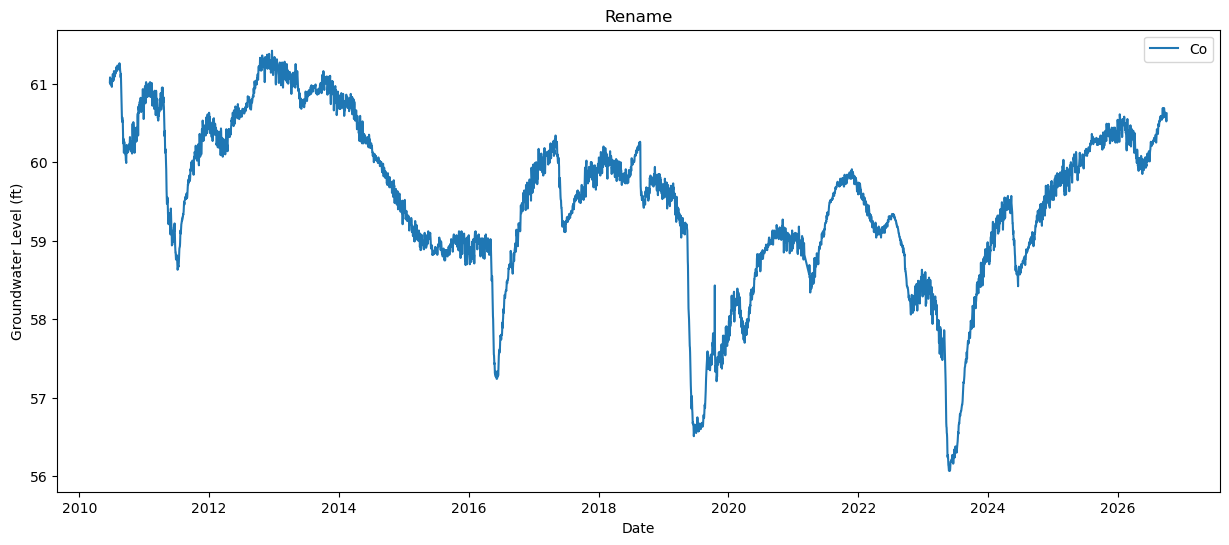

In [14]:
plt.figure(figsize=(15,6))
plt.plot(df_gwl_co['date'], df_gwl_co['gwl'], label='Co')
plt.xlabel('Date')
plt.ylabel('Groundwater Level (ft)')
plt.title('Rename')
plt.legend()
plt.show()

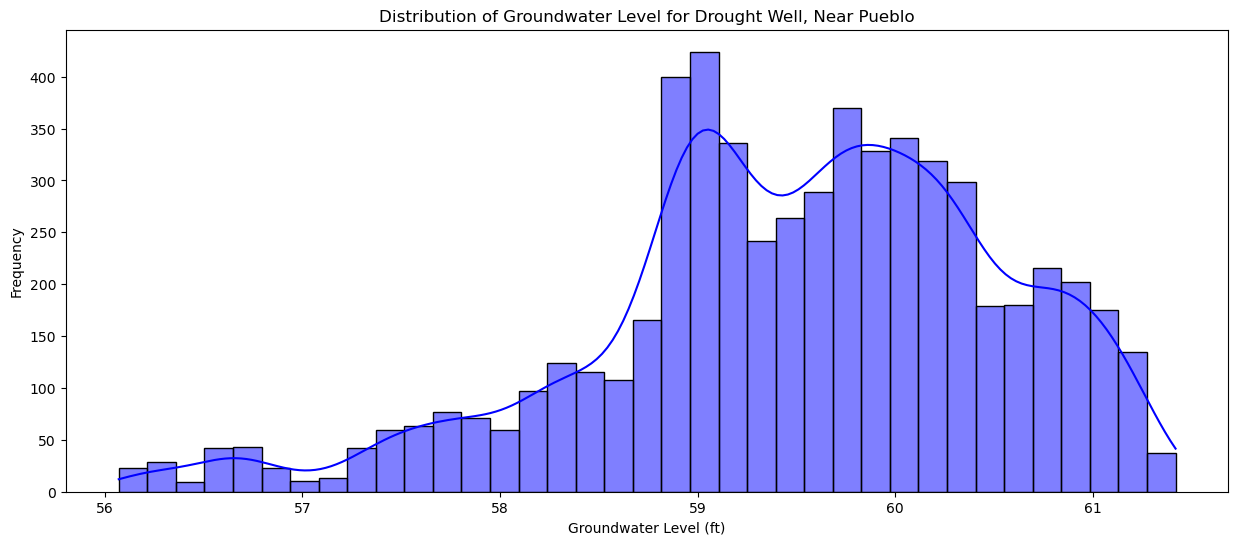

In [15]:
plt.figure(figsize=(15,6))
sns.histplot(df_gwl_co['gwl'], kde=True, color='blue')
plt.xlabel('Groundwater Level (ft)')
plt.ylabel('Frequency')
plt.title('Distribution of Groundwater Level for Drought Well, Near Pueblo')
plt.show()

In [16]:
df_gwl_co['date'] = pd.to_datetime(
    df_gwl_co['date'],
    errors='coerce'
)

In [19]:
gwl_monthly = (df_gwl_co
    .set_index('date')
    .resample('MS')['gwl']
    .mean()
    .reset_index()
)

In [20]:
# Daily dataset
df_gwl_co.to_parquet(
    r"C:\Users\katel\extreme climate\data\gwl_daily.parquet",
    index=False
)

# Monthly dataset
gwl_monthly.to_parquet(
    r"C:\Users\katel\extreme climate\data\gwl_monthly.parquet",
    index=False
)